Imports and Configuration

In [1]:
import os
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

# CONFIGURATION

DATA_PATH = "data/processed/paddy_cleaned.csv"
TRAIN_DATA_PATH = "data/processed/train_data.csv"

OUTPUT_DIR = "experiments/xgboost"
os.makedirs(OUTPUT_DIR, exist_ok=True)

TARGET = "Production 000 Mt."

FEATURES = [
    "Year",
    "production_lag_1",
    "production_lag_2",
    "production_lag_3",
    "rolling_mean_3",
    "rolling_std_3"
]

# Conservative configuration for a small dataset
XGB_PARAMETERS = {
    "n_estimators": 100,
    "max_depth": 2,
    "learning_rate": 0.03,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_lambda": 5,
    "reg_alpha": 0.1,
    "objective": "reg:squarederror",
    "random_state": 42,
    "n_jobs": -1
}

Data loading

In [2]:
def load_data():

    data = pd.read_csv(DATA_PATH)
    data["Year"] = pd.to_numeric(data["Year"]).astype(int)
    data[TARGET] = pd.to_numeric(data[TARGET]).astype(float)

    data = data.sort_values("Year").reset_index(drop=True)

    return data


def get_split_year():

    train_data = pd.read_csv(TRAIN_DATA_PATH)

    return int(train_data["Year"].max())


data = load_data()

print("Dataset loaded:", data.shape)
print("Historical period:", data["Year"].min(), "-", data["Year"].max())
print("Training split year:", get_split_year())

data.head()

Dataset loaded: (61, 2)
Historical period: 1952 - 2012
Training split year: 2000


,Year,Production 000 Mt.
0,1952,604.0
1,1953,458.0
2,1954,650.0
3,1955,747.0
4,1956,574.0


Feature engineering

In [3]:
def create_features(history, next_year):

    values = history[TARGET].astype(float).values

    if len(values) < 3:
        raise ValueError("At least 3 historical values are required.")

    return pd.DataFrame([{
        "Year": next_year,
        "production_lag_1": values[-1],
        "production_lag_2": values[-2],
        "production_lag_3": values[-3],
        "rolling_mean_3": np.mean(values[-3:]),
        "rolling_std_3": np.std(values[-3:], ddof=1)
    }])

Model training

In [4]:
def train_model(history):

    features = []
    targets = []

    for i in range(3, len(history)):

        previous_values = history[TARGET].iloc[:i].values

        features.append({
            "Year": int(history["Year"].iloc[i]),
            "production_lag_1": previous_values[-1],
            "production_lag_2": previous_values[-2],
            "production_lag_3": previous_values[-3],
            "rolling_mean_3": np.mean(previous_values[-3:]),
            "rolling_std_3": np.std(previous_values[-3:], ddof=1)
        })

        targets.append(float(history[TARGET].iloc[i]))

    X = pd.DataFrame(features)[FEATURES]
    y = np.array(targets)

    model = XGBRegressor(**XGB_PARAMETERS)
    model.fit(X, y)

    return model

Evaluation metrics

In [5]:
def calculate_metrics(actual, predicted):

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    mape = np.mean(
        np.abs((np.array(actual) - np.array(predicted))
               / np.array(actual))
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    }

Experiment A: Walk-forward evaluation

In [6]:
def walk_forward_evaluation(data):

    split_year = get_split_year()

    history = data[data["Year"] <= split_year].copy()
    test_data = data[data["Year"] > split_year].copy()

    predictions = []

    for _, row in test_data.iterrows():

        next_year = int(row["Year"])

        model = train_model(history)

        X_next = create_features(history, next_year)[FEATURES]

        prediction = float(model.predict(X_next)[0])

        predictions.append({
            "Year": next_year,
            "Actual": float(row[TARGET]),
            "Predicted": prediction
        })

        # Reveal actual value after prediction
        new_row = pd.DataFrame([{
            "Year": next_year,
            TARGET: float(row[TARGET])
        }])

        history = pd.concat(
            [history, new_row],
            ignore_index=True
        )

    results = pd.DataFrame(predictions)

    metrics = calculate_metrics(
        results["Actual"],
        results["Predicted"]
    )

    results.to_csv(
        f"{OUTPUT_DIR}/walk_forward_predictions.csv",
        index=False
    )

    print("\n========== XGBOOST WALK-FORWARD ==========")

    for name, value in metrics.items():
        print(f"{name}: {value:.2f}")

    return results, metrics


walk_results, walk_metrics = walk_forward_evaluation(data)
display(walk_results)



========== XGBOOST WALK-FORWARD ==========
MAE: 635.20
RMSE: 704.21
MAPE: 18.11


,Year,Actual,Predicted
0,2001,2695.0,2243.662842
1,2002,2860.0,2415.124512
2,2003,3067.0,2497.890381
3,2004,2628.0,2571.985840
4,2005,3246.0,2561.516602
5,2006,3341.0,2638.878906
6,2007,3131.0,2708.659424
7,2008,3875.0,2748.690674
8,2009,3652.0,2939.421387
9,2010,4301.0,3044.990723


Experiment B: Fixed-origin recursive evaluation

In [7]:
def recursive_forecast(history, forecast_years):

    history = history.copy()
    predictions = []

    model = train_model(history)

    for year in forecast_years:

        X_next = create_features(history, int(year))[FEATURES]

        prediction = float(model.predict(X_next)[0])

        predictions.append({
            "Year": int(year),
            "Predicted": prediction
        })

        # Add predicted value, not actual value
        new_row = pd.DataFrame([{
            "Year": int(year),
            TARGET: prediction
        }])

        history = pd.concat(
            [history, new_row],
            ignore_index=True
        )

    return pd.DataFrame(predictions)


def fixed_origin_evaluation(data):

    split_year = get_split_year()

    history = data[data["Year"] <= split_year].copy()
    test_data = data[data["Year"] > split_year].copy()

    forecast_years = test_data["Year"].tolist()

    predictions = recursive_forecast(
        history,
        forecast_years
    )

    results = predictions.merge(
        test_data[["Year", TARGET]],
        on="Year"
    )

    results = results.rename(
        columns={TARGET: "Actual"}
    )

    metrics = calculate_metrics(
        results["Actual"],
        results["Predicted"]
    )

    results.to_csv(
        f"{OUTPUT_DIR}/fixed_origin_predictions.csv",
        index=False
    )

    print("\n========== XGBOOST FIXED-ORIGIN ==========")

    for name, value in metrics.items():
        print(f"{name}: {value:.2f}")

    return results, metrics


fixed_results, fixed_metrics = fixed_origin_evaluation(data)
display(fixed_results)


========== XGBOOST FIXED-ORIGIN ==========
MAE: 953.39
RMSE: 1069.61
MAPE: 26.69


,Year,Predicted,Actual
0,2001,2243.662842,2695.0
1,2002,2356.884033,2860.0
2,2003,2437.047852,3067.0
3,2004,2461.294434,2628.0
4,2005,2461.294434,3246.0
5,2006,2448.013184,3341.0
6,2007,2448.013184,3131.0
7,2008,2448.013184,3875.0
8,2009,2448.013184,3652.0
9,2010,2448.013184,4301.0


Feature importance and model saving

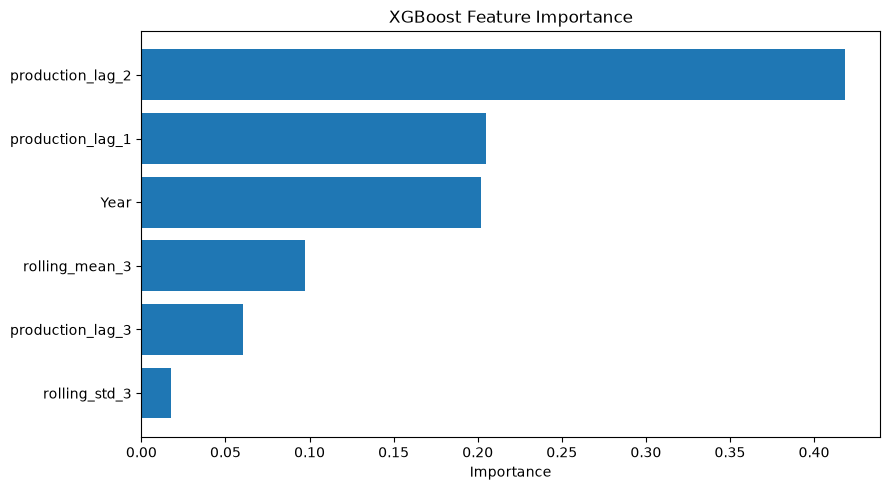

,Feature,Importance
2,production_lag_2,0.418315
1,production_lag_1,0.204717
0,Year,0.201953
4,rolling_mean_3,0.097341
3,production_lag_3,0.060217
5,rolling_std_3,0.017456


In [8]:
def save_feature_importance(data):

    model = train_model(data)

    importance = pd.DataFrame({
        "Feature": FEATURES,
        "Importance": model.feature_importances_
    }).sort_values(
        "Importance",
        ascending=False
    )

    importance.to_csv(
        f"{OUTPUT_DIR}/feature_importance.csv",
        index=False
    )

    plt.figure(figsize=(9, 5))

    plt.barh(
        importance["Feature"],
        importance["Importance"]
    )

    plt.gca().invert_yaxis()

    plt.title("XGBoost Feature Importance")
    plt.xlabel("Importance")
    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/feature_importance.png",
        dpi=300
    )

    plt.show()
    plt.close()

    return model, importance


final_model, feature_importance = save_feature_importance(data)

joblib.dump(
    final_model,
    f"{OUTPUT_DIR}/xgboost_model.pkl"
)

display(feature_importance)

Actual vs predicted visualization

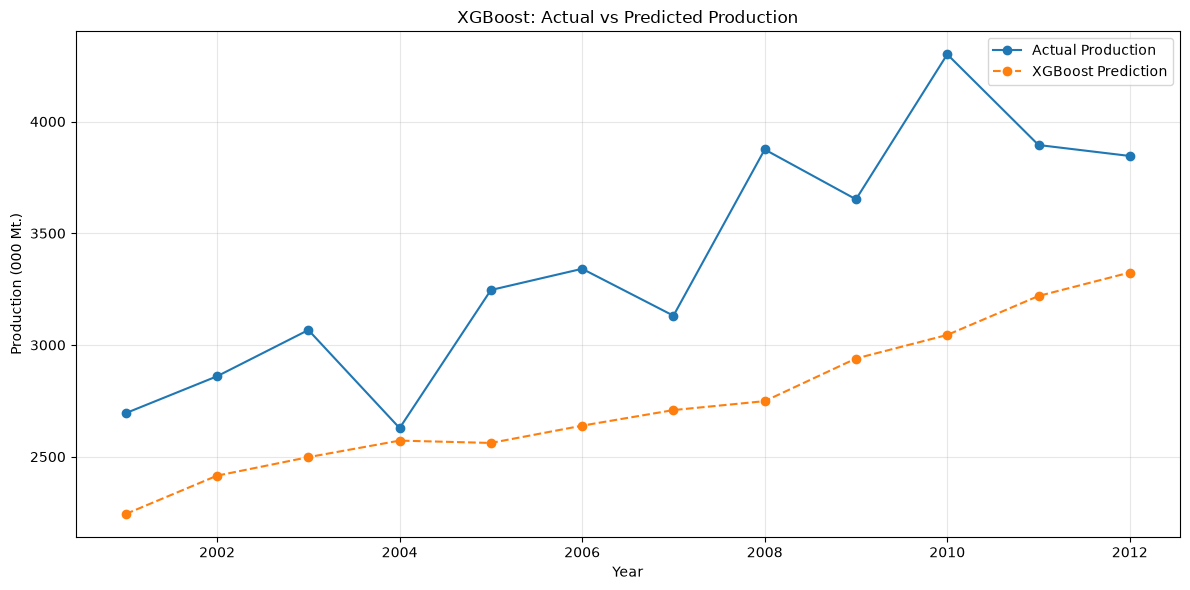

In [9]:
def plot_predictions(results):

    plt.figure(figsize=(12, 6))

    plt.plot(
        results["Year"],
        results["Actual"],
        marker="o",
        label="Actual Production"
    )

    plt.plot(
        results["Year"],
        results["Predicted"],
        marker="o",
        linestyle="--",
        label="XGBoost Prediction"
    )

    plt.title("XGBoost: Actual vs Predicted Production")
    plt.xlabel("Year")
    plt.ylabel("Production (000 Mt.)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/actual_vs_predicted.png",
        dpi=300
    )

    plt.show()
    plt.close()


plot_predictions(walk_results)

Future 10 years forecasting

In [10]:
def future_forecast(data):

    model_history = data.copy()

    future_years = range(
        int(data["Year"].max()) + 1,
        int(data["Year"].max()) + 11
    )

    forecast = recursive_forecast(
        model_history,
        future_years
    )

    forecast["Horizon"] = (
        forecast["Year"] - int(data["Year"].max())
    )

    forecast.to_csv(
        f"{OUTPUT_DIR}/future_forecast.csv",
        index=False
    )

    print("\n========== XGBOOST FUTURE FORECAST ==========")

    print(forecast.to_string(index=False))

    return forecast


future_results = future_forecast(data)
display(future_results)


========== XGBOOST FUTURE FORECAST ==========
 Year   Predicted  Horizon
 2013 3398.135254        1
 2014 3391.964844        2
 2015 3391.964844        3
 2016 3383.743896        4
 2017 3383.743896        5
 2018 3383.743896        6
 2019 3383.743896        7
 2020 3383.743896        8
 2021 3383.743896        9
 2022 3383.743896       10


,Year,Predicted,Horizon
0,2013,3398.135254,1
1,2014,3391.964844,2
2,2015,3391.964844,3
3,2016,3383.743896,4
4,2017,3383.743896,5
5,2018,3383.743896,6
6,2019,3383.743896,7
7,2020,3383.743896,8
8,2021,3383.743896,9
9,2022,3383.743896,10
